In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("./insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.duplicated().sum()

np.int64(1)

In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df.shape

(1337, 7)

In [6]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')

In [7]:
df["sex"].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [8]:
def plotting(var, num):
  plt.subplot(2,2,num)
  sns.histplot(df[var], kde=True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 83.6 KB


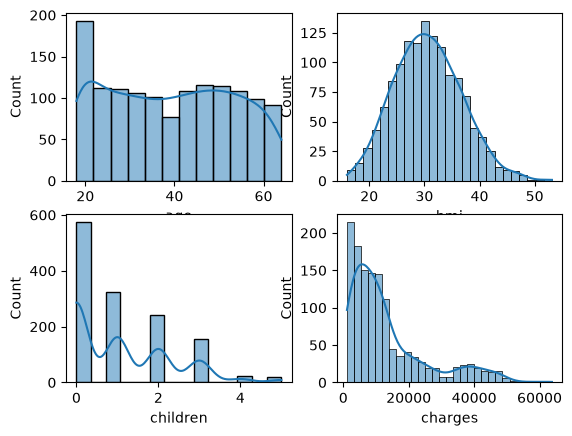

In [10]:
plotting("age", 1)
plotting("bmi", 2)
plotting("children", 3)
plotting("charges", 4)

In [11]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [12]:
df_cleaned = df.copy()

In [13]:
df_cleaned.drop_duplicates(inplace=True)

In [14]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [15]:
df_cleaned["smoker"] = df_cleaned["smoker"].map({"yes": 1, "no": 0})

In [16]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,1,southwest,16884.92400
1,18,male,33.770,1,0,southeast,1725.55230
2,28,male,33.000,3,0,southeast,4449.46200
3,33,male,22.705,0,0,northwest,21984.47061
4,32,male,28.880,0,0,northwest,3866.85520


In [17]:
df_cleaned["sex"].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [18]:
df_cleaned["sex"] = df_cleaned["sex"].map({"female": 1, "male": 0})

In [19]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [20]:
df_cleaned["children"].value_counts()

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [21]:
df_cleaned = pd.get_dummies(df_cleaned, columns=["region"], dtype=int)

In [22]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


In [23]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'],
      dtype='str')

In [24]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1337 non-null   int64  
 1   sex               1337 non-null   int64  
 2   bmi               1337 non-null   float64
 3   children          1337 non-null   int64  
 4   smoker            1337 non-null   int64  
 5   charges           1337 non-null   float64
 6   region_northeast  1337 non-null   int64  
 7   region_northwest  1337 non-null   int64  
 8   region_southeast  1337 non-null   int64  
 9   region_southwest  1337 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 114.9 KB


In [25]:
df_cleaned.isnull().sum()

age                 0
sex                 0
bmi                 0
children            0
smoker              0
charges             0
region_northeast    0
region_northwest    0
region_southeast    0
region_southwest    0
dtype: int64

In [26]:
df_cleaned["children"].value_counts()

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [27]:
df_cleaned["bmi"].head()

0    27.900
1    33.770
2    33.000
3    22.705
4    28.880
Name: bmi, dtype: float64

In [28]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


In [29]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'],
      dtype='str')

In [30]:
bins = [0, 18.5, 24.9, 29.9, 100]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df_cleaned["bmi_category"] = pd.cut(df_cleaned["bmi"], labels=labels, bins=bins)

In [31]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,0,1,0,Obese
2,28,0,33.000,3,0,4449.46200,0,0,1,0,Obese
3,33,0,22.705,0,0,21984.47061,0,1,0,0,Normal
4,32,0,28.880,0,0,3866.85520,0,1,0,0,Overweight


<Axes: xlabel='bmi', ylabel='Count'>

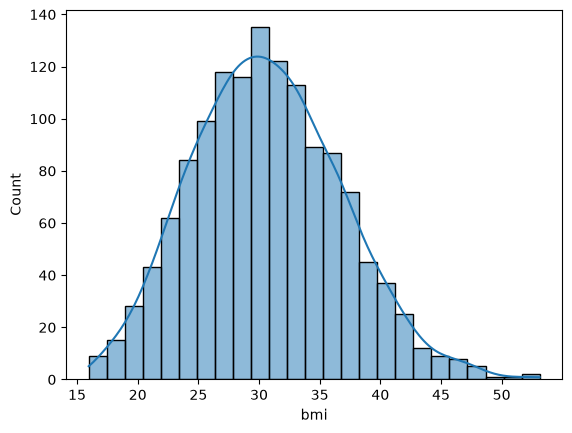

In [32]:
sns.histplot(df_cleaned["bmi"], kde=True)

In [33]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,0,1,0,Obese
2,28,0,33.000,3,0,4449.46200,0,0,1,0,Obese
3,33,0,22.705,0,0,21984.47061,0,1,0,0,Normal
4,32,0,28.880,0,0,3866.85520,0,1,0,0,Overweight


In [34]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   age               1337 non-null   int64   
 1   sex               1337 non-null   int64   
 2   bmi               1337 non-null   float64 
 3   children          1337 non-null   int64   
 4   smoker            1337 non-null   int64   
 5   charges           1337 non-null   float64 
 6   region_northeast  1337 non-null   int64   
 7   region_northwest  1337 non-null   int64   
 8   region_southeast  1337 non-null   int64   
 9   region_southwest  1337 non-null   int64   
 10  bmi_category      1337 non-null   category
dtypes: category(1), float64(2), int64(8)
memory usage: 116.4 KB


In [35]:
df_cleaned = pd.get_dummies(df_cleaned, columns=["bmi_category"], dtype=int)

In [36]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,1,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,0,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,0,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,0,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0,0,0,1,0


In [37]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='str')

In [38]:
scaler = StandardScaler()
numeric_cols = ["age", "bmi", "children"]
df_cleaned[numeric_cols] = scaler.fit_transform(df_cleaned[numeric_cols])

In [39]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0


In [40]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       1337 non-null   float64
 1   sex                       1337 non-null   int64  
 2   bmi                       1337 non-null   float64
 3   children                  1337 non-null   float64
 4   smoker                    1337 non-null   int64  
 5   charges                   1337 non-null   float64
 6   region_northeast          1337 non-null   int64  
 7   region_northwest          1337 non-null   int64  
 8   region_southeast          1337 non-null   int64  
 9   region_southwest          1337 non-null   int64  
 10  bmi_category_Underweight  1337 non-null   int64  
 11  bmi_category_Normal       1337 non-null   int64  
 12  bmi_category_Overweight   1337 non-null   int64  
 13  bmi_category_Obese        1337 non-null   int64  
dtypes: float64(4), int64(10)

In [41]:
selected_features = [
  'age', 'sex', 'bmi', 'children', 'smoker',
  'region_northeast', 'region_northwest', 'region_southeast',
  'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
  'bmi_category_Overweight', 'bmi_category_Obese']

correlation = {
  feature: pearsonr(df_cleaned[feature], df_cleaned["charges"])[0] for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlation.items()), columns=["Feature", "Pearson Correlation"])
correlation_df.sort_values(by="Pearson Correlation", ascending=False, inplace=True)
correlation_df

,Feature,Pearson Correlation
4,smoker,0.787234
0,age,0.298308
2,bmi,0.198401
12,bmi_category_Obese,0.197659
7,region_southeast,0.073578
3,children,0.067389
5,region_northeast,0.005945
6,region_northwest,-0.038695
8,region_southwest,-0.043637
9,bmi_category_Underweight,-0.048225


In [42]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0


In [43]:
df_cleaned["charges_bins"] = pd.qcut(df_cleaned["charges"], q=4, labels=False)
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,charges_bins
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0,3
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0,3
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0,0


In [44]:
cat_cols = ["sex", "children", "smoker", "region_northeast", "region_northwest", "region_southeast", "region_southwest", "bmi_category_Underweight", "bmi_category_Normal", "bmi_category_Overweight", "bmi_category_Obese"]
alpha = 0.05

contingency_table = {}

for col in cat_cols:
  contingency = pd.crosstab(df_cleaned[col], df_cleaned["charges_bins"])
  chi2, p_value, _, _ = chi2_contingency(contingency)
  decision = "Reject null (Keep Feature)" if p_value < alpha else "Accept Null (Drop Feature)"
  contingency_table[col] = {
    "chi2": chi2,
    "p_value": p_value,
    "decision": decision
  }

In [45]:
contingency_table

{'sex': {'chi2': np.float64(10.258784131896034),
  'p_value': np.float64(0.016489740254825715),
  'decision': 'Reject null (Keep Feature)'},
 'children': {'chi2': np.float64(138.65931339918984),
  'p_value': np.float64(4.2307493321985393e-22),
  'decision': 'Reject null (Keep Feature)'},
 'smoker': {'chi2': np.float64(848.2191784691495),
  'p_value': np.float64(1.5074776554531107e-183),
  'decision': 'Reject null (Keep Feature)'},
 'region_northeast': {'chi2': np.float64(6.438442307376374),
  'p_value': np.float64(0.09212205767134672),
  'decision': 'Accept Null (Drop Feature)'},
 'region_northwest': {'chi2': np.float64(1.1342403613235656),
  'p_value': np.float64(0.76881540917986),
  'decision': 'Accept Null (Drop Feature)'},
 'region_southeast': {'chi2': np.float64(15.998167448977355),
  'p_value': np.float64(0.0011349657141180654),
  'decision': 'Reject null (Keep Feature)'},
 'region_southwest': {'chi2': np.float64(5.091893034250699),
  'p_value': np.float64(0.16519063312163623),
 

In [46]:
chi2_results_df = pd.DataFrame(contingency_table).T
chi2_results_df.sort_values(by="decision", ascending=False, inplace=True)
chi2_results_df

,chi2,p_value,decision
sex,10.258784,0.01649,Reject null (Keep Feature)
children,138.659313,0.0,Reject null (Keep Feature)
smoker,848.219178,0.0,Reject null (Keep Feature)
region_southeast,15.998167,0.001135,Reject null (Keep Feature)
region_northeast,6.438442,0.092122,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Underweight,4.384749,0.222804,Accept Null (Drop Feature)
bmi_category_Normal,4.263673,0.234364,Accept Null (Drop Feature)
bmi_category_Overweight,4.201575,0.240504,Accept Null (Drop Feature)


In [47]:
correlation_df

,Feature,Pearson Correlation
4,smoker,0.787234
0,age,0.298308
2,bmi,0.198401
12,bmi_category_Obese,0.197659
7,region_southeast,0.073578
3,children,0.067389
5,region_northeast,0.005945
6,region_northwest,-0.038695
8,region_southwest,-0.043637
9,bmi_category_Underweight,-0.048225


In [48]:
final_df = df_cleaned[["smoker", "age", "bmi", "bmi_category_Obese", "sex", "children", "region_southeast", "region_northeast", "charges"]]
final_df.head()

,smoker,age,bmi,bmi_category_Obese,sex,children,region_southeast,region_northeast,charges
0,1,-1.440418,-0.453160,0,1,-0.909234,0,0,16884.92400
1,0,-1.511647,0.509422,1,0,-0.079442,1,0,1725.55230
2,0,-0.799350,0.383155,1,0,1.580143,1,0,4449.46200
3,0,-0.443201,-1.305052,0,0,-0.909234,0,0,21984.47061
4,0,-0.514431,-0.292456,0,0,-0.909234,0,0,3866.85520


In [49]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,charges_bins
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0,3
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0,3
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0,0


In [50]:
X = final_df[["smoker", "age", "bmi", "bmi_category_Obese", "sex", "children", "region_southeast", "region_northeast"]]
y = final_df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [51]:
X_train

,smoker,age,bmi,bmi_category_Obese,sex,children,region_southeast,region_northeast
1114,0,-1.155499,-1.009063,0,0,-0.909234,0,1
968,0,-1.297958,-0.806543,0,0,0.750351,0,1
599,0,0.910164,1.125178,1,1,0.750351,0,0
170,0,1.693691,1.772092,1,0,-0.909234,1,0
275,0,0.554015,-0.666338,0,1,0.750351,0,1
...,...,...,...,...,...,...,...,...
1096,1,0.838934,0.704562,1,1,0.750351,0,1
1131,0,-0.870580,2.498538,1,0,0.750351,0,0
1295,0,-1.369188,-1.420660,0,0,-0.079442,0,0
861,0,-0.087053,-0.436761,0,1,1.580143,0,0


In [52]:
y_train

1114     2396.09590
968      3279.86855
599     33471.97189
170     13405.39030
275      9715.84100
           ...     
1096    44641.19740
1131     3693.42800
1295     1964.78000
861      7151.09200
1127     5836.52040
Name: charges, Length: 1069, dtype: float64

In [53]:
X_test

,smoker,age,bmi,bmi_category_Obese,sex,children,region_southeast,region_northeast
900,0,0.696474,-1.336209,0,0,-0.909234,0,1
1064,0,-0.728120,-0.830321,0,1,2.409936,0,0
1256,0,0.838934,0.938238,1,1,1.580143,0,0
298,1,-0.585661,0.611091,1,0,1.580143,0,0
237,0,-0.585661,1.267024,1,0,0.750351,1,0
...,...,...,...,...,...,...,...,...
534,0,1.764921,1.609749,1,0,-0.909234,1,0
542,0,1.693691,0.924299,1,1,-0.909234,1,0
760,0,-1.226729,0.642248,1,1,0.750351,0,1
1284,1,1.551231,0.924299,1,0,-0.079442,0,0


In [54]:
y_test

900      8688.85885
1064     5708.86700
1256    11436.73815
298     38746.35510
237      4463.20510
           ...     
534     13831.11520
542     13887.20400
760      3925.75820
1284    47403.88000
1285     8534.67180
Name: charges, Length: 268, dtype: float64

In [55]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[23045.99, 3479.62, 688.5 ,..., 647.91, -135.47, 578.31]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['smoker','age','bmi',...,'children','region_southeast','region_northeast']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6716
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [56]:
y_pred = model.predict(X_test)
y_pred[:20]

array([ 8209.07325913,  5221.61850546, 14412.47498417, 32227.09824224,
        8959.62010586, 13321.60498502, 30591.46638904,  1189.3675889 ,
       11134.81948321,  9940.81977616, 10493.18496832, 31967.32307454,
       31892.20008662, 16137.86679359, 10680.58746445,  8412.91204573,
        5222.54197208, 32347.08480153,  3139.20708052,  3923.74672786])

In [57]:
X_test.head()

,smoker,age,bmi,bmi_category_Obese,sex,children,region_southeast,region_northeast
900,0,0.696474,-1.336209,0,0,-0.909234,0,1
1064,0,-0.728120,-0.830321,0,1,2.409936,0,0
1256,0,0.838934,0.938238,1,1,1.580143,0,0
298,1,-0.585661,0.611091,1,0,1.580143,0,0
237,0,-0.585661,1.267024,1,0,0.750351,1,0


In [58]:
single_prediction = model.predict(X_test.head())
single_prediction

array([ 8209.07325913,  5221.61850546, 14412.47498417, 32227.09824224,
        8959.62010586])

In [59]:
final_df.loc[900]

smoker                   0.000000
age                      0.696474
bmi                     -1.336209
bmi_category_Obese       0.000000
sex                      0.000000
children                -0.909234
region_southeast         0.000000
region_northeast         1.000000
charges               8688.858850
Name: 900, dtype: float64

In [60]:
r2 = r2_score(y_test, y_pred=y_pred)
r2
n = X_test.shape[0]
p = X_test.shape[1]

In [61]:
adjusted_r2 = 1 - ((1 - r2)*(n - 1) / (n - p - 1))
adjusted_r2

0.7987454347255233